# 06 Roads, rail and transit


In [1]:
from common import *
import duckdb
b = pd.read_parquet(OUT / "base_table.parquet")
s = b[b.region.isin(SCORED)]
K = ["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "unclassified"]
km = b.groupby("region")[[f"road_km_{k}" for k in K]].sum().loc[REG]; km.columns = K
print("km by class:"); print(km.round(0).astype(int).to_string())
print("\nshare of km by class (%):"); print((100 * km.div(km.sum(axis=1), axis=0)).round(1).to_string())

km by class:
                  motorway  trunk  primary  secondary  tertiary  residential  unclassified
region                                                                                    
maricopa-az           5533   2991     5819       7771     13120        65245         23040
northern-ca           2437   2005     3010       4752     10828        37892         16522
eastern-ok            5917   4288     6205      11536     14081       131424         39869
south-central-tx     20453  16289    23696      57761     51826       373520         32748
eastern-wa            1995   1883     3014       5149     12651        24812         29657

share of km by class (%):
                  motorway  trunk  primary  secondary  tertiary  residential  unclassified
region                                                                                    
maricopa-az          4.500  2.400    4.700      6.300    10.600       52.800        18.700
northern-ca          3.100  2.600    3.900      6.

**Takeaway:** Residential roads make up 49% to 65% of drivable length in the four scored regions (31% in Eastern WA, where unclassified roads are 37.5%). The four highway classes together are 13.1% of length in Eastern OK, 15.7% in Northern CA, 17.9% in Maricopa and 20.4% in Texas, driven by Texas's much larger secondary share (10.0% against 5.4% to 6.5% elsewhere). The class mix, and so what counts as "highway-class", is not uniform across regions, which echoes the organisers' warning that road gaps are not comparable across regions.

## 1. What the drivable filter removes
`roads` keeps seven drivable classes; `roads-unfiltered` keeps everything. Length by group, by region.

In [2]:
g = b.groupby("region")[["road_km_all", "ru_km_all", "ru_km_service", "ru_km_track", "ru_km_nonmotor", "ru_km_unknown"]].sum().loc[REG]
g["other_removed"] = g.ru_km_all - g.road_km_all - g.ru_km_service - g.ru_km_track - g.ru_km_nonmotor
print(g.round(0).astype(int).to_string())
print("\nshare of unfiltered km kept by the filter (%):", (100 * g.road_km_all / g.ru_km_all).round(1).to_dict())
print("share of removed km that is service (%):", (100 * g.ru_km_service / (g.ru_km_all - g.road_km_all)).round(1).to_dict())

                  road_km_all  ru_km_all  ru_km_service  ru_km_track  ru_km_nonmotor  ru_km_unknown  other_removed
region                                                                                                            
maricopa-az            123519     319803          53093        99819           41283           2015           2088
northern-ca             77447     201036          26417        78079           18305            773            787
eastern-ok             213319     311989          71502        17473            7999           1497           1697
south-central-tx       576292    1041796         286510       110593           58809           9564           9592
eastern-wa              79160     187609          30932        53781           22971            740            765

share of unfiltered km kept by the filter (%): {'maricopa-az': 38.6, 'northern-ca': 38.5, 'eastern-ok': 68.4, 'south-central-tx': 55.3, 'eastern-wa': 42.2}
share of removed km that is service (%

## 2. Highway-class roads: presence and density
A tract with no motorway, trunk, primary or secondary segment has nothing for the road component to compare (if the reference also has none, the component is undefined). Share of such tracts by region, by urban class, and the density where they exist.

share of tracts with any highway-class road:
region
maricopa-az        0.979
northern-ca        0.988
eastern-ok         0.977
south-central-tx   0.989
eastern-wa         0.988

by urban class (scored four):
              tracts  has_hwy  median_hwy_km  median_land
ur                                                       
Rural           1712    0.985         43.127      207.281
Urban           7641    0.987          6.234        2.834
unclassified      26    0.731          1.792        3.482

where present: median km 8.02 | p90 49.3 | median km per km2 1.422

highway-class pieces per tract with a highway (median): 51.0 | tracts with exactly one piece: 20


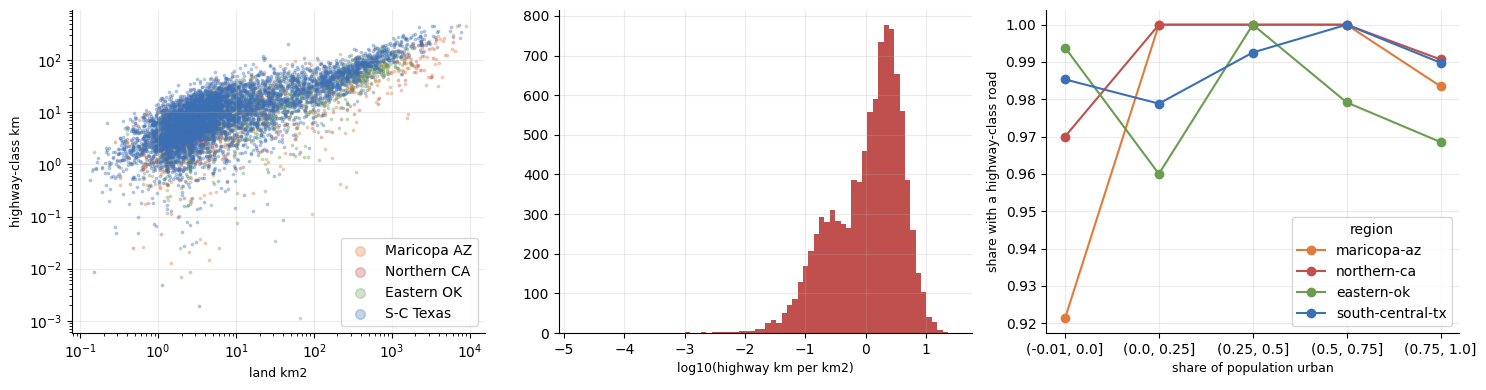

In [3]:
s2 = b.assign(ur=b.ur_class.fillna("unclassified"), has_hwy=b.road_km_hwy > 0)
print("share of tracts with any highway-class road:"); print(s2.groupby("region").has_hwy.mean().loc[REG].round(3).to_string())
print("\nby urban class (scored four):"); print(s2[s2.region.isin(SCORED)].groupby(["ur"]).agg(tracts=("GEOID", "size"), has_hwy=("has_hwy", "mean"), median_hwy_km=("road_km_hwy", "median"), median_land=("land_km2", "median")).round(3).to_string())
x = s2[s2.has_hwy]
print("\nwhere present: median km", round(x.road_km_hwy.median(), 2), "| p90", round(x.road_km_hwy.quantile(.9), 1), "| median km per km2", round(x.road_hwy_km_per_km2.median(), 3))
print("\nhighway-class pieces per tract with a highway (median):", x.road_n_hwy_pieces.median(), "| tracts with exactly one piece:", int((x.road_n_hwy_pieces == 1).sum()))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for r in SCORED: q = x[x.region == r]; ax[0].scatter(q.land_km2, q.road_km_hwy, s=3, alpha=.3, c=COL[r], label=NAME[r])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("land km2"); ax[0].set_ylabel("highway-class km"); ax[0].legend(markerscale=4)
ax[1].hist(np.log10(x.road_hwy_km_per_km2), bins=70, color="#c0504d"); ax[1].set_xlabel("log10(highway km per km2)")
sh = s2.groupby(["region", pd.cut(s2.pct_urban.fillna(0), [-0.01, 0, .25, .5, .75, 1])]).has_hwy.mean().unstack(0)[SCORED]; sh.plot(ax=ax[2], marker="o", color=[COL[r] for r in SCORED]); ax[2].set_xlabel("share of population urban"); ax[2].set_ylabel("share with a highway-class road")
plt.show()

**Takeaway:** Overture has a highway-class road in 97.7% to 98.9% of tracts in every region, and equally in rural (98.5%) and urban (98.7%) tracts, so presence does not separate them; the amount does (median 43 km in rural tracts, 6 km in urban, reflecting their 207 km2 against 2.8 km2 median land). Where a highway-class road exists, the median tract has 8.0 km in 51 pieces, and 20 tracts have exactly one piece. The organisers report that over half of Maricopa has no named-highway road in the reference, yet Overture has one in 97.9% of Maricopa tracts, so the undefined-component pattern comes from the reference side and cannot be read off Overture's road layer.

## 3. Road density and urbanity
Total drivable km per km2 against how urban the tract is, and how the class mix shifts.

In [4]:
q = s2[(s2.region.isin(SCORED))]
print(q.groupby("ur").agg(tracts=("GEOID", "size"), km_per_km2=("road_km_per_km2", "median"), hwy_share=("road_km_hwy", "sum"), all_km=("road_km_all", "sum")).assign(hwy_share=lambda d: d.hwy_share / d.all_km).drop(columns="all_km").round(3).to_string())
print("\nSpearman with population density:", {v: round(q[v].corr(q.pop_per_km2, method="spearman"), 3) for v in ["road_km_per_km2", "road_hwy_km_per_km2", "bldg_per_km2"]})
print("Spearman of highway km with land area:", round(q.road_km_hwy.corr(q.land_km2, method="spearman"), 3), "| of all road km with land area:", round(q.road_km_all.corr(q.land_km2, method="spearman"), 3))

              tracts  km_per_km2  hwy_share
ur                                         
Rural           1712       1.281      0.160
Urban           7641       9.969      0.226
unclassified      26       1.931      0.158



Spearman with population density: {'road_km_per_km2': np.float64(0.842), 'road_hwy_km_per_km2': np.float64(0.65), 'bldg_per_km2': np.float64(0.878)}
Spearman of highway km with land area: 0.712 | of all road km with land area: 0.944


**Takeaway:** Urban tracts have about eight times the road density of rural ones (median 10.0 against 1.3 km per km2), and a larger highway share of length (22.6% against 16.0%). Total road km tracks land area closely (Spearman 0.94) and density tracks building density (0.88) and population density (0.84); highway km follows land area (0.71) and population density less closely (0.65), so highway km is the more region- and geometry-dependent target.

## 4. Who supplies the segments, and attribute completeness
Supplier of the drivable segments (10% sample), with how often speed limits, surface, names and routes are filled.

In [5]:
c = duckdb.connect(); c.sql("load spatial")
RF = lambda r: f"read_parquet('{(REF/r/f'{r}-overture-roads.parquet').as_posix()}')"
rows = [c.sql(f"""select '{r}' region, sources[1].dataset supplier, count(*) n, avg((coalesce(len(speed_limits), 0) > 0)::int) speed, avg((coalesce(len(road_surface), 0) > 0)::int) surface,
          avg((names."primary" is not null)::int) named, avg((coalesce(len(routes), 0) > 0)::int) routed, avg((coalesce(len(road_flags), 0) > 0)::int) flagged
          from (select * from {RF(r)} using sample 10% (reservoir, 7)) group by 2""").df() for r in REG]
rs = pd.concat(rows); rs["share"] = rs.n / rs.groupby("region").n.transform("sum")
print(rs.pivot(index="supplier", columns="region", values="share")[REG].fillna(0).round(3).to_string())
print("\ncompleteness by supplier (weighted over regions):")
print(rs.groupby("supplier").apply(lambda d: pd.Series({k: np.average(d[k].astype(float), weights=d.n) for k in ["speed", "surface", "named", "routed", "flagged"]} | {"n": d.n.sum()})).round(3).to_string())
byclass = pd.concat([c.sql(f"select '{r}' region, class, avg((names.\"primary\" is not null)::int) named, avg((coalesce(len(speed_limits), 0) > 0)::int) speed, count(*) n from (select * from {RF(r)} using sample 10% (reservoir, 7)) group by 2").df() for r in SCORED])
print("\ncompleteness by class (four scored regions pooled):")
print(byclass.groupby("class").apply(lambda d: pd.Series({k: np.average(d[k].astype(float), weights=d.n) for k in ["named", "speed"]} | {"n": d.n.sum()})).round(3).to_string())

region         maricopa-az  northern-ca  eastern-ok  south-central-tx  eastern-wa
supplier                                                                         
OpenStreetMap        0.999        1.000       1.000             0.999       0.999
TomTom               0.001        0.000       0.000             0.001       0.001

completeness by supplier (weighted over regions):
               speed  surface  named  routed  flagged           n
supplier                                                         
OpenStreetMap  0.271    0.297  0.824   0.089    0.041 328,384.000
TomTom         0.000    0.000  0.000   0.000    0.404     270.000



completeness by class (four scored regions pooled):
              named  speed           n
class                                 
motorway      0.329  0.451   4,364.000
primary       0.755  0.457  11,220.000
residential   0.830  0.242 221,656.000
secondary     0.829  0.381  29,342.000
tertiary      0.913  0.288  29,698.000
trunk         0.583  0.479   4,897.000
unclassified  0.697  0.197  13,212.000


## 5. Rail and transit infrastructure
Rail length and the infrastructure layer (bus stops, stations, airports), as tract presence and as density.

In [6]:
r5 = b.assign(has_rail=b.rail_km > 0, has_transit=b.infra_n_transit > 0, has_airport=b.infra_n_airport > 0, has_bus=b.infra_n_busstop > 0)
print(r5.groupby("region")[["has_rail", "has_transit", "has_bus", "has_airport"]].mean().loc[REG].round(3).to_string())
print("\ntotals: rail km", b.groupby("region").rail_km.sum().loc[REG].round(0).to_dict()); print("infrastructure features", b.groupby("region").infra_n.sum().loc[REG].astype(int).to_dict())
print("\nby urban class (scored four): share with bus stop / rail")
print(r5[r5.region.isin(SCORED)].assign(ur=lambda d: d.ur_class.fillna("unclassified")).groupby("ur")[["has_bus", "has_rail", "has_airport"]].mean().round(3).to_string())
print("\nrail km per tract, where present (median):", round(b[b.rail_km > 0].rail_km.median(), 2))

                  has_rail  has_transit  has_bus  has_airport
region                                                       
maricopa-az          0.239        0.608    0.592        0.176
northern-ca          0.472        0.607    0.597        0.223
eastern-ok           0.569        0.193    0.182        0.318
south-central-tx     0.404        0.236    0.222        0.201
eastern-wa           0.624        0.600    0.578        0.373

totals: rail km {'maricopa-az': 6529.0, 'northern-ca': 4033.0, 'eastern-ok': 11915.0, 'south-central-tx': 27111.0, 'eastern-wa': 6421.0}
infrastructure features {'maricopa-az': 9509, 'northern-ca': 3327, 'eastern-ok': 2735, 'south-central-tx': 13737, 'eastern-wa': 4139}

by urban class (scored four): share with bus stop / rail
              has_bus  has_rail  has_airport
ur                                          
Rural           0.043     0.675        0.596
Urban           0.362     0.341        0.126
unclassified    0.231     0.231        0.577

rail km pe